BÀI 6 (Trang 26): Giảm số màu trong ảnh bằng k-Means

Cell 0: Import thư viện (không cần chụp)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans

In [2]:
from google.colab import files
uploaded = files.upload()               # chọn 1 ảnh từ máy
ten_anh = list(uploaded.keys())[0]      # tự lấy tên file vừa tải lên
print("Đã tải lên:", ten_anh)

Saving Husky.jpg to Husky.jpg
Đã tải lên: Husky.jpg


Bước 1: Đọc ảnh gốc và hiển thị

Lê Anh Pha - 6451071056


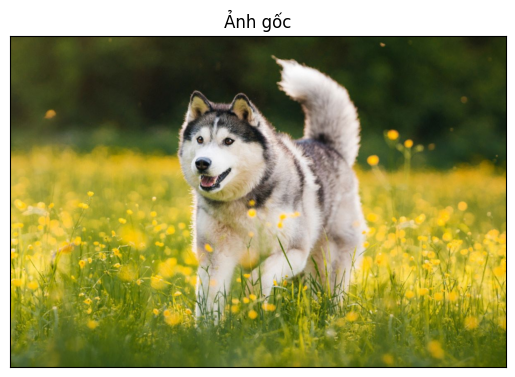

Kích thước file gốc: 125.6 KB


In [3]:
print("Lê Anh Pha - 6451071056")

# convert('RGB') để đảm bảo ảnh có đúng 3 kênh màu (bỏ kênh trong suốt nếu có)
image = Image.open(ten_anh).convert('RGB')

axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.title('Ảnh gốc')
plt.show()

print("Kích thước file gốc:", round(os.path.getsize(ten_anh) / 1024, 1), "KB")

Bước 2: Chuyển ảnh thành mảng số, lấy chiều rộng và cao

In [4]:
print("Lê Anh Pha - 6451071056")

imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]

print("imarr.shape:", imarr.shape, "(cao, rộng, 3 kênh màu)")
print("Chiều cao (rows):", rows)
print("Chiều rộng (cols):", cols)
print("Số màu khác nhau trong ảnh gốc:", len(np.unique(imarr.reshape(-1, 3), axis=0)))

Lê Anh Pha - 6451071056
imarr.shape: (800, 1200, 3) (cao, rộng, 3 kênh màu)
Chiều cao (rows): 800
Chiều rộng (cols): 1200
Số màu khác nhau trong ảnh gốc: 164074


Bước 3: Chuẩn hóa về [0,1] và chuyển mảng 3 chiều thành 2 chiều

In [5]:
print("Lê Anh Pha - 6451071056")

data = imarr / 255.0                  # đưa giá trị màu về đoạn [0...1]
data = data.reshape(rows * cols, 3)   # (cao, rộng, 3) -> (cao x rộng, 3)

print("data.shape:", data.shape)

Lê Anh Pha - 6451071056
data.shape: (960000, 3)


Bước 4: Chạy k-Means với số màu mong muốn là 32

In [6]:
print("Lê Anh Pha - 6451071056")

kmeans = KMeans(n_clusters=32, max_iter=300, n_init=3, random_state=42)
kmeans.fit(data)

# Mỗi pixel được thay bằng màu của tâm cụm mà nó thuộc về
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

print("Gom cụm xong.")
print("new_colors.shape:", new_colors.shape)
print("Số màu sau khi gom cụm:", len(np.unique(new_colors, axis=0)))

Lê Anh Pha - 6451071056
Gom cụm xong.
new_colors.shape: (960000, 3)
Số màu sau khi gom cụm: 32


In [7]:
from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(n_clusters=32, random_state=42)

Bước 5: Khôi phục dạng mảng 3 chiều

In [8]:
print("Lê Anh Pha - 6451071056")

img_recolored = new_colors.reshape(imarr.shape)
print("img_recolored.shape:", img_recolored.shape)

Lê Anh Pha - 6451071056
img_recolored.shape: (800, 1200, 3)


Bước 6: So sánh ảnh gốc và ảnh 32 màu

Lê Anh Pha - 6451071056


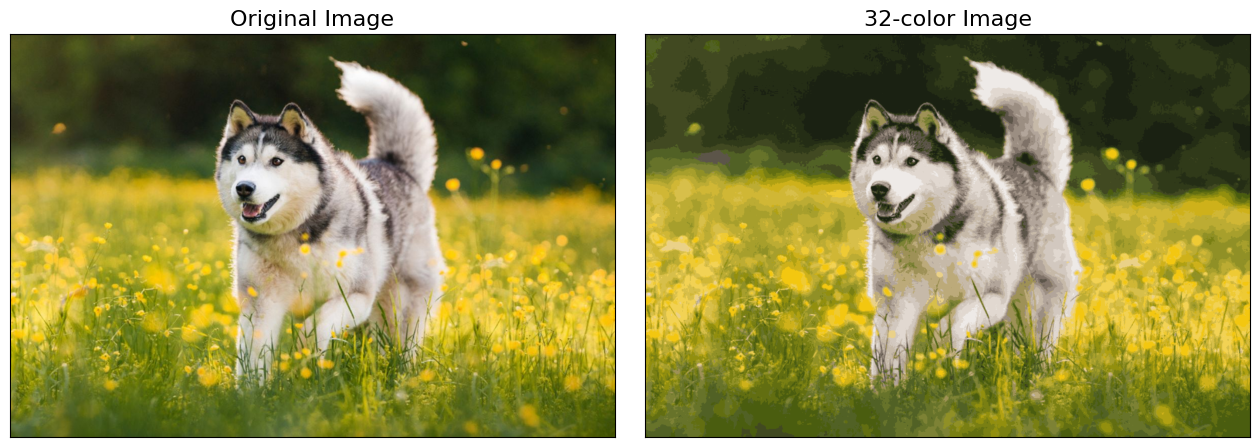

In [9]:
print("Lê Anh Pha - 6451071056")

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image', size=16)
plt.show()

Bước 7: Lưu ảnh kết quả xuống đĩa và so sánh dung lượng

In [10]:
print("Lê Anh Pha - 6451071056")

img_save = img_recolored * 255
new_img = Image.fromarray(img_save.astype(np.uint8))
new_img.save('compressed_img2.png')

kb_goc = os.path.getsize(ten_anh) / 1024
kb_moi = os.path.getsize('compressed_img2.png') / 1024
print(f"Dung lượng ảnh gốc     : {kb_goc:.1f} KB")
print(f"Dung lượng ảnh 32 màu  : {kb_moi:.1f} KB")
print(f"Thay đổi               : {(kb_moi - kb_goc) / kb_goc * 100:+.1f}%")

Lê Anh Pha - 6451071056
Dung lượng ảnh gốc     : 125.6 KB
Dung lượng ảnh 32 màu  : 288.4 KB
Thay đổi               : +129.6%
